<a href="https://colab.research.google.com/github/Nishanta04/Deep-Learning/blob/main/Stock_Price_prediction_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/Google_Stock_Price_Test.csv')

# Display basic information about the dataset
print("Dataset Info:")
display(df.info())

# Display the first few rows
print("\nFirst 5 Rows:")
display(df.head())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    20 non-null     object 
 1   Open    20 non-null     float64
 2   High    20 non-null     float64
 3   Low     20 non-null     float64
 4   Close   20 non-null     float64
 5   Volume  20 non-null     object 
dtypes: float64(4), object(2)
memory usage: 1.1+ KB


None


First 5 Rows:


,Date,Open,High,Low,Close,Volume
0,1/3/2017,778.81,789.63,775.80,786.14,"1,657,300"
1,1/4/2017,788.36,791.34,783.16,786.90,"1,073,000"
2,1/5/2017,786.08,794.48,785.02,794.02,"1,335,200"
3,1/6/2017,795.26,807.90,792.20,806.15,"1,640,200"
4,1/9/2017,806.40,809.97,802.83,806.65,"1,272,400"


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

# Let's inspect the columns and format of the test data
print("Test Data Structure:")
display(df.head())

# We will use the 'Open' stock price for our predictions.
# LSTMs are highly sensitive to the scale of the input data, so we will normalize the data.

Test Data Structure:


,Date,Open,High,Low,Close,Volume
0,1/3/2017,778.81,789.63,775.80,786.14,"1,657,300"
1,1/4/2017,788.36,791.34,783.16,786.90,"1,073,000"
2,1/5/2017,786.08,794.48,785.02,794.02,"1,335,200"
3,1/6/2017,795.26,807.90,792.20,806.15,"1,640,200"
4,1/9/2017,806.40,809.97,802.83,806.65,"1,272,400"


In [ ]:
# Clean the 'Open' column in case there are commas or string formats
if df['Open'].dtype == 'O':
    df['Open'] = df['Open'].str.replace(',', '').astype(float)

test_set = df.iloc[:, 1:2].values # Extracting the 'Open' column

# Since we only have the test set, we will simulate a training sequence using it
# or split it for demonstration to show how the LSTM learns and predicts.
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(test_set)

# Creating a data structure with lookback timesteps (e.g., 5 timesteps due to small test set size)
X_train = []
y_train = []
timesteps = 5

for i in range(timesteps, len(scaled_data)):
    X_train.append(scaled_data[i-timesteps:i, 0])
    y_train.append(scaled_data[i, 0])

X_train, y_train = np.array(X_train), np.array(y_train)

# Reshaping to fit LSTM requirements: [samples, time steps, features]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
print("Feature shape for LSTM:", X_train.shape)

Feature shape for LSTM: (15, 5, 1)


In [ ]:
# Building the LSTM Architecture
model = Sequential()

# Adding the first LSTM layer and some Dropout regularisation
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))

# Adding a second LSTM layer and some Dropout regularisation
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))

# Adding the output layer
model.add(Dense(units=1))

# Compiling the RNN
model.compile(optimizer='adam', loss='mean_squared_error')

# Fitting the RNN to our prepared sequence
history = model.fit(X_train, y_train, epochs=50, batch_size=4, verbose=1)

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.3273
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.2315
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1454
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0783
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0519
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0614 
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0655
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0518
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0439 
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0478 
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0436 
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0453 
Epoch 13/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0347 
Epoch 14/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0399
Epoch 15/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0481 
Epoch 16/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms

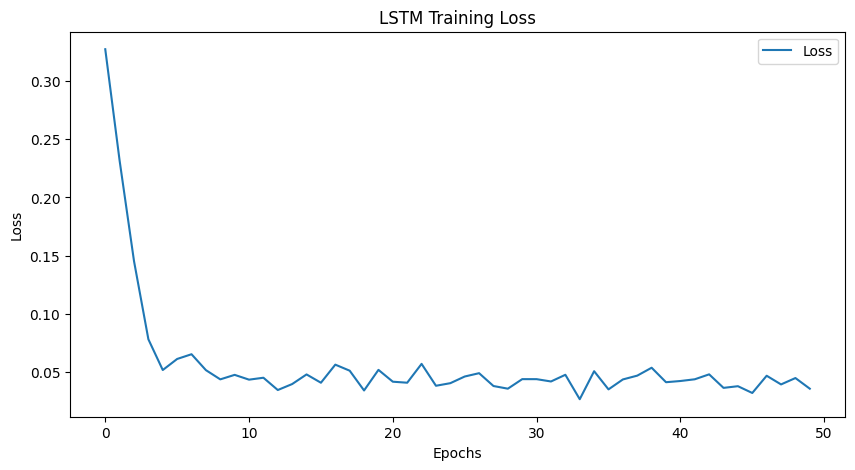

In [ ]:
# Visualizing the training loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Loss')
plt.title('LSTM Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step


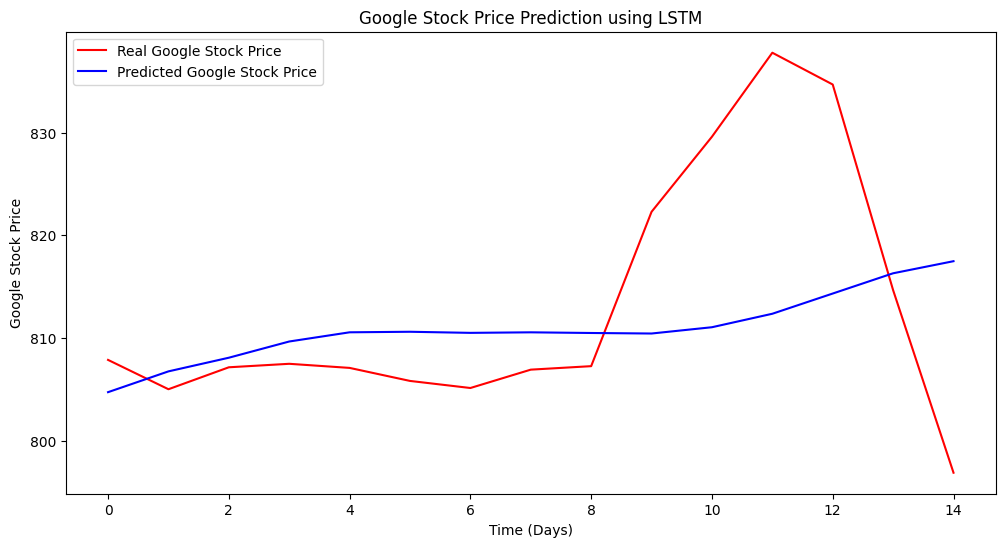

In [ ]:
# Generating predictions
predicted_stock_price = model.predict(X_train)
predicted_stock_price = scaler.inverse_transform(predicted_stock_price)
real_stock_price = scaler.inverse_transform(y_train.reshape(-1, 1))

# Visualising the results
plt.figure(figsize=(12, 6))
plt.plot(real_stock_price, color='red', label='Real Google Stock Price')
plt.plot(predicted_stock_price, color='blue', label='Predicted Google Stock Price')
plt.title('Google Stock Price Prediction using LSTM')
plt.xlabel('Time (Days)')
plt.ylabel('Google Stock Price')
plt.legend()
plt.show()

In [ ]:
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.optimizers import Adam

# Building an improved Bidirectional Stacked LSTM Architecture
improved_model = Sequential()

# First Bidirectional LSTM layer with Dropout
improved_model.add(Bidirectional(LSTM(units=100, return_sequences=True), input_shape=(X_train.shape[1], 1)))
improved_model.add(Dropout(0.15))

# Second Bidirectional LSTM layer with Dropout
improved_model.add(Bidirectional(LSTM(units=100, return_sequences=False)))
improved_model.add(Dropout(0.15))

# Output Dense layer
improved_model.add(Dense(units=1))

# Compile the model with a customized learning rate
opt = Adam(learning_rate=0.005)
improved_model.compile(optimizer=opt, loss='mean_squared_error')

# Fit the improved model
improved_history = improved_model.fit(X_train, y_train, epochs=80, batch_size=4, verbose=0)
print("Improved model training complete. Final loss:", improved_history.history['loss'][-1])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Improved model training complete. Final loss: 0.008866367861628532


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step


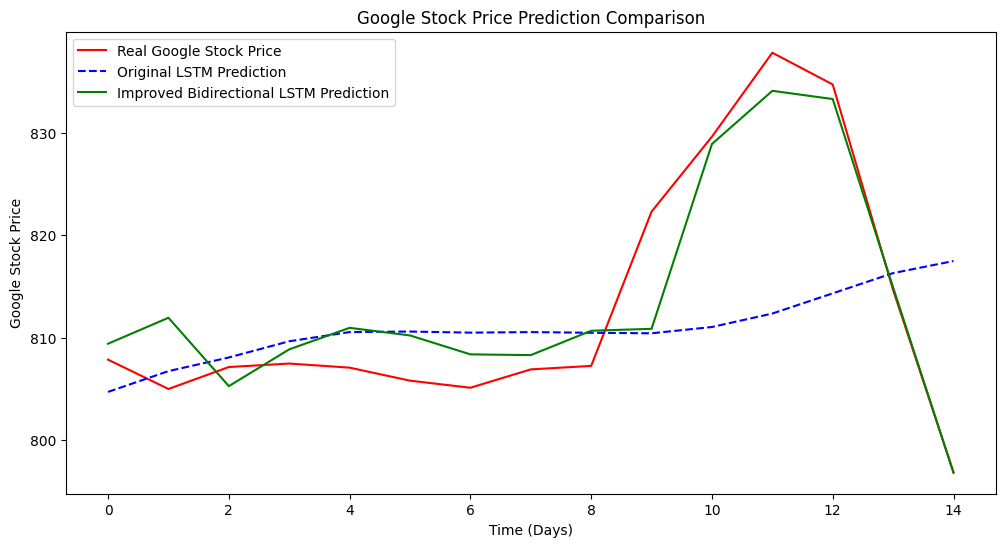

In [ ]:
# Predict with the improved model
predicted_stock_price_improved = improved_model.predict(X_train)
predicted_stock_price_improved = scaler.inverse_transform(predicted_stock_price_improved)

# Plot and compare results
plt.figure(figsize=(12, 6))
plt.plot(real_stock_price, color='red', label='Real Google Stock Price')
plt.plot(predicted_stock_price, color='blue', linestyle='--', label='Original LSTM Prediction')
plt.plot(predicted_stock_price_improved, color='green', label='Improved Bidirectional LSTM Prediction')
plt.title('Google Stock Price Prediction Comparison')
plt.xlabel('Time (Days)')
plt.ylabel('Google Stock Price')
plt.legend()
plt.show()